<a href="https://colab.research.google.com/github/sebastianvettel1212/scikit-learn-cookbook/blob/main/scikit_learn_Cookbook_Chapter6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/sebastianvettel1212/scikit-learn-cookbook/blob/main/scikit_learn_Cookbook_Chapter6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 6 — Regresi Logistik Lanjutan dan Ekstensinya (*Advanced Logistic Regression and Extensions*)

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing)

Notebook ini berisi:
1. **Reproduksi kode** seluruh *recipe* Bab 6 (dari repositori resmi buku, termasuk solusi latihan),
2. **Ringkasan** tiap subbab, dan
3. **Penjelasan teori** dalam Bahasa Indonesia.

> Sel berlabel **"Tambahan"** adalah contoh pelengkap yang tidak ada di buku. Perbaikan kecil terhadap kode asli buku (mis. `import` yang kurang atau sintaks yang sudah tidak berlaku di versi scikit-learn terbaru) ditandai dengan komentar `# Catatan:` di dalam sel.

---

## Daftar Isi
0. Persiapan
1. Ikhtisar Regresi Logistik (*Overview of Logistic Regression*)
2. Teknik Klasifikasi Multikelas (*Multiclass Classification Techniques*)
3. Regularisasi pada Regresi Logistik (*Regularization in Logistic Regression*)
4. Konsep Klasifikasi Multilabel (*Multilabel Classification Concepts*)
5. Metrik Evaluasi Model (*Model Evaluation Metrics*)
6. Latihan Praktik
7. Ringkasan Bab

---

## Pengantar
Pada Bab 5 kita memakai regresi untuk memprediksi nilai **kontinu**. Namun banyak masalah nyata (spam atau bukan, pasien sakit atau sehat, jenis bunga) adalah masalah **klasifikasi**. **Regresi logistik** adalah model linear untuk klasifikasi: ia memprediksi **probabilitas** sebuah data masuk ke suatu kelas. Bab ini memperdalamnya lewat empat hal: **multikelas**, **regularisasi**, **multilabel**, dan **metrik evaluasi** (bagian "*Implementation in scikit-learn*" pada daftar bab buku dikerjakan di sepanjang semua subbab, bukan sebagai subbab terpisah).

## 0. Persiapan

In [1]:
pip install numpy pandas scikit-learn matplotlib seaborn

In [2]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print('Versi scikit-learn:', sklearn.__version__)

def styled_report(report_dict):
    """Ubah classification_report(output_dict=True) menjadi tabel berwarna."""
    df_ = pd.DataFrame(report_dict).transpose()
    return (df_.style
        .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

Versi scikit-learn: 1.6.1


---
## 1. Ikhtisar Regresi Logistik (*Overview of Logistic Regression*)

### Teori
Regresi linear memprediksi angka bebas ($-\infty$ sampai $+\infty$), sehingga tidak cocok untuk probabilitas yang harus berada di $[0,1]$. Regresi logistik memecahkannya dengan menerapkan **fungsi logistik (sigmoid)** pada kombinasi linear fitur:

$$P(Y=1\mid X)=\sigma(z)=\frac{1}{1+e^{-z}},\qquad z=\beta_0+\beta_1x_1+\dots+\beta_px_p$$

- **Odds** adalah rasio peluang kejadian terhadap peluang tidak terjadi: $\text{odds}=\dfrac{p}{1-p}$.
- **Log-odds (logit)** adalah $\ln\dfrac{p}{1-p}=z$. Artinya model logistik sebenarnya **linear dalam log-odds**: batas keputusannya tetap berupa garis/bidang lurus, hanya skala outputnya yang dipetakan ke probabilitas.
- **Interpretasi koefisien:** menaikkan $x_j$ sebesar satu satuan mengalikan *odds* dengan $e^{\beta_j}$ (*odds ratio*).
- **Estimasi parameter** memakai ***Maximum Likelihood Estimation (MLE)***, yaitu mencari $\beta$ yang memaksimalkan peluang data teramati. Ini setara meminimalkan ***log-loss*** (*cross-entropy*):
$$\mathcal{L}=-\frac1n\sum_{i=1}^{n}\Big[y_i\ln p_i+(1-y_i)\ln(1-p_i)\Big]$$
  Tidak ada rumus tertutup seperti OLS, sehingga dipakai optimasi iteratif (*solver*) seperti `lbfgs` atau `liblinear`; itu sebabnya ada parameter `max_iter`.
- **Aturan keputusan:** kelas 1 bila $p\ge$ ambang (umumnya 0,5), selain itu kelas 0. Ambang ini bisa digeser sesuai biaya kesalahan.

### Getting ready
Kita memakai dataset **Breast Cancer Wisconsin** bawaan scikit-learn (569 sampel, 30 fitur numerik). Label `0` = *malignant* (ganas), `1` = *benign* (jinak).

In [3]:
# Load libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Convert to DataFrame for easier manipulation (optional)
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y

# Split the Data
X_train, X_test, y_train, y_test = train_test_split(df[data.feature_names],
                                                    df['target'],
                                                    test_size=0.2,
                                                    random_state=2024)
print('Bentuk data latih:', X_train.shape, '| data uji:', X_test.shape)
print('Distribusi kelas (0=ganas, 1=jinak):', dict(zip(*np.unique(y, return_counts=True))))

Bentuk data latih: (455, 30) | data uji: (114, 30)
Distribusi kelas (0=ganas, 1=jinak): {np.int64(0): np.int64(212), np.int64(1): np.int64(357)}


### How to do it
Memakai model di scikit-learn cukup membuat objek kelasnya, lalu `fit()` dan `predict()`. Kita evaluasi dengan akurasi, *confusion matrix*, dan *classification report*.

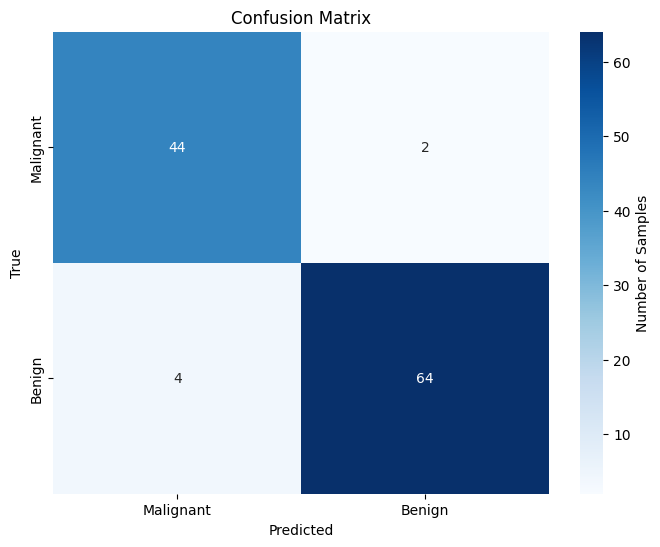

Accuracy: 0.95


Classification Report:


,precision,recall,f1-score,support
Malignant,0.917,0.957,0.936,46
Benign,0.970,0.941,0.955,68
accuracy,0.947,0.947,0.947,1
macro avg,0.943,0.949,0.946,114
weighted avg,0.948,0.947,0.948,114


In [4]:
# Create a Logistic Regression Model
model = LogisticRegression(max_iter=10000)  # Increase max_iter if convergence issues occur

# Train the Model
model.fit(X_train, y_train)

# Make Predictions
y_pred = model.predict(X_test)

# Evaluate Performance
accuracy = accuracy_score(y_test, y_pred)

# Generate and plot confusion matrix
class_names = ['Malignant', 'Benign']
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Get classification report as a dictionary
report_dict = classification_report(y_test, y_pred,
                                    target_names=class_names,
                                    output_dict=True)

print(f'Accuracy: {accuracy:.2f}\n')
print("\nClassification Report:")
display(styled_report(report_dict))

**Interpretasi:** akurasi ≈ **0,95** (0,947) pada 114 data uji. Dari *confusion matrix*: **44 dari 46** tumor ganas dan **64 dari 68** tumor jinak diklasifikasikan benar; hanya 2 ganas yang diprediksi jinak dan 4 jinak yang diprediksi ganas. Kelas *Malignant* punya *recall* 0,957 dan *precision* 0,917; kelas *Benign* punya *recall* 0,941 dan *precision* 0,970.

**Menjawab pertanyaan buku** ("metrik lain apa yang lebih baik daripada akurasi?"): pada skrining kanker, kesalahan paling berbahaya adalah **tumor ganas yang lolos sebagai jinak**. Maka yang perlu dipantau adalah ***recall* kelas Malignant** (sering disebut *sensitivity* untuk kasus ganas), bukan sekadar akurasi keseluruhan.

### Tambahan: kurva sigmoid dan log-odds
Dua grafik ini memperlihatkan mengapa model disebut "linear dalam log-odds".

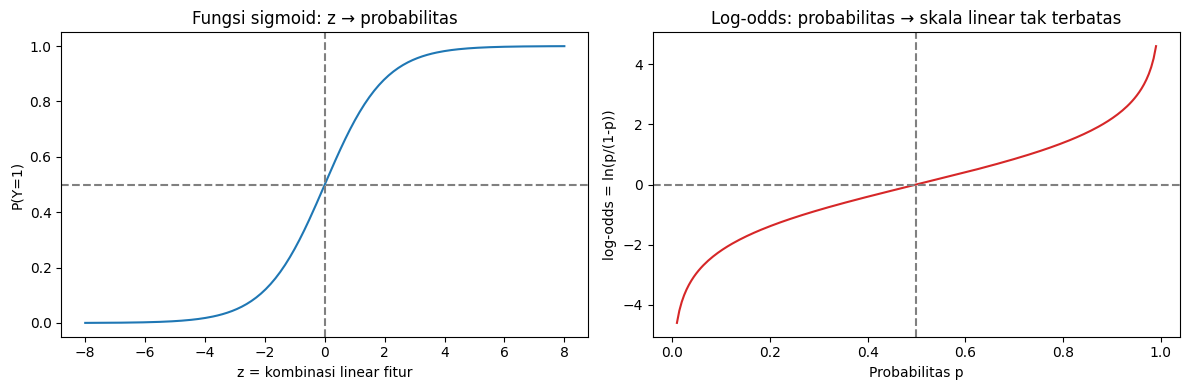

In [5]:
# Tambahan (tidak ada di kode buku): visualisasi sigmoid dan log-odds
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))

p = np.linspace(0.01, 0.99, 200)
log_odds = np.log(p / (1 - p))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(z, sigmoid, color='tab:blue')
ax[0].axhline(0.5, color='gray', linestyle='--'); ax[0].axvline(0, color='gray', linestyle='--')
ax[0].set_xlabel('z = kombinasi linear fitur'); ax[0].set_ylabel('P(Y=1)')
ax[0].set_title('Fungsi sigmoid: z → probabilitas')

ax[1].plot(p, log_odds, color='tab:red')
ax[1].axhline(0, color='gray', linestyle='--'); ax[1].axvline(0.5, color='gray', linestyle='--')
ax[1].set_xlabel('Probabilitas p'); ax[1].set_ylabel('log-odds = ln(p/(1-p))')
ax[1].set_title('Log-odds: probabilitas → skala linear tak terbatas')
plt.tight_layout(); plt.show()

### Tambahan: probabilitas prediksi dan pengaruh ambang keputusan
`predict()` memakai ambang 0,5, padahal `predict_proba()` memberi probabilitasnya. Pada kasus medis, **salah memprediksi tumor ganas sebagai jinak** jauh lebih berbahaya daripada sebaliknya. Pertanyaan buku ("metrik lain apa yang lebih baik?") dijawab di sini: perhatikan *recall* kelas Malignant.

In [6]:
# Tambahan (tidak ada di kode buku): geser ambang keputusan
y_prob = model.predict_proba(X_test)[:, 1]   # P(Benign)
print('5 probabilitas pertama P(Benign):', np.round(y_prob[:5], 3))

rows = []
for t in [0.3, 0.5, 0.7, 0.9]:
    y_t = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_t).ravel()
    rows.append({'Ambang': t,
                 'Akurasi': (tn + tp) / len(y_test),
                 'Recall Malignant': tn / (tn + fp),
                 'Recall Benign': tp / (tp + fn),
                 'Ganas lolos (ganas diprediksi jinak)': fp,
                 'Jinak salah (jinak diprediksi ganas)': fn})
pd.DataFrame(rows).set_index('Ambang').round(3)

5 probabilitas pertama P(Benign): [0.    0.    0.984 1.    0.987]


,Akurasi,Recall Malignant,Recall Benign,Ganas lolos (ganas diprediksi jinak),Jinak salah (jinak diprediksi ganas)
Ambang,,,,,
0.3,0.930,0.913,0.941,4,4
0.5,0.947,0.957,0.941,2,4
0.7,0.930,0.957,0.912,2,6
0.9,0.912,0.978,0.868,1,9


**Interpretasi:** ambang 0,5 memberi akurasi tertinggi (0,947), tetapi bukan satu-satunya pilihan. Bila ambang untuk memutuskan "jinak" dinaikkan, model makin hati-hati: jumlah **ganas yang lolos** turun dari 4 (ambang 0,3) menjadi 2 (ambang 0,5 dan 0,7) lalu 1 (ambang 0,9), sedangkan jumlah **jinak yang salah dianggap ganas** naik dari 4 menjadi 9 dan akurasi turun ke 0,912. Inilah ***trade-off* precision-recall**: menurunkan salah satu jenis kesalahan hampir selalu menaikkan jenis lainnya. Karena data uji hanya 114 sampel, selisih 1–2 kasus belum bisa dianggap pasti; yang penting adalah pola arahnya.

### Tambahan: menafsirkan koefisien sebagai *odds ratio*
Agar koefisien dapat dibandingkan, fitur distandardisasi lebih dulu sehingga setiap koefisien berarti "perubahan log-odds untuk kenaikan 1 simpangan baku".

In [7]:
# Tambahan (tidak ada di kode buku): koefisien terstandardisasi -> odds ratio
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000)).fit(X_train, y_train)
print(f'Akurasi uji pipeline (scaling + logistic regression): {pipe.score(X_test, y_test):.3f}')

coef = pd.Series(pipe[-1].coef_[0], index=data.feature_names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(8)
pd.DataFrame({'koefisien (per 1 SD)': top, 'odds ratio = exp(koef)': np.exp(top)}).round(3)

Akurasi uji pipeline (scaling + logistic regression): 0.982


,koefisien (per 1 SD),odds ratio = exp(koef)
worst texture,-1.336,0.263
radius error,-1.265,0.282
worst radius,-1.027,0.358
worst area,-0.933,0.393
mean concave points,-0.924,0.397
mean concavity,-0.847,0.429
worst concavity,-0.846,0.429
worst concave points,-0.845,0.430


**Interpretasi:** dengan standardisasi, akurasi uji naik menjadi ≈ **0,98** (dibanding 0,95 tanpa *scaling*), sekaligus *solver* lebih mudah konvergen. Delapan koefisien terbesar semuanya **negatif**, karena kelas 1 = *Benign*: semakin besar nilai fitur seperti `worst texture`, `radius error`, `worst radius`, `worst area`, atau fitur *concavity*, semakin **turun** *odds* tumor jinak. Contohnya `worst texture` memiliki *odds ratio* ≈ 0,26: kenaikan satu simpangan baku mengalikan *odds* jinak dengan ≈ 0,26 (turun ≈ 74%). **Peringatan:** fitur seperti radius, perimeter, dan area saling berkorelasi kuat, sehingga koefisien individunya tidak boleh ditafsirkan terpisah; inilah alasan regularisasi (subbab 3) berguna.

### How it works
Regresi logistik memperkirakan probabilitas lewat kombinasi linear fitur yang dilewatkan ke fungsi logistik. Koefisien menunjukkan seberapa besar tiap fitur menggeser **log-odds** kelas positif. *Decision boundary*-nya linear dalam ruang fitur, tetapi probabilitas keluarannya melengkung (sigmoid).

**Metrik evaluasi** yang dibahas buku:

| Metrik | Rumus | Arti |
|---|---|---|
| Akurasi | $\dfrac{TP+TN}{TP+TN+FP+FN}$ | Proporsi prediksi benar (menyesatkan bila kelas tak seimbang) |
| Precision | $\dfrac{TP}{TP+FP}$ | Dari yang diprediksi positif, berapa yang benar |
| Recall | $\dfrac{TP}{TP+FN}$ | Dari yang sebenarnya positif, berapa yang tertangkap |
| F1-score | $\dfrac{2\cdot P\cdot R}{P+R}$ | Rata-rata harmonik precision dan recall |

### Key Ideas
- Regresi logistik = model **linear dalam log-odds** yang menghasilkan **probabilitas** lewat sigmoid.
- Parameter dicari dengan MLE (meminimalkan log-loss) menggunakan *solver* iteratif.
- Akurasi saja tidak cukup; pilih metrik sesuai biaya kesalahan, dan **ambang keputusan** dapat disetel.

---
## 2. Teknik Klasifikasi Multikelas (*Multiclass Classification Techniques*)

### Teori
Regresi logistik aslinya biner. Untuk $K>2$ kelas ada dua strategi utama:

| Strategi | Cara kerja | Catatan |
|---|---|---|
| **One-vs-Rest (OvR / One-vs-All)** | Melatih $K$ klasifikasi biner; tiap kelas dilawankan dengan semua kelas lain. Prediksi = kelas dengan skor tertinggi | Sederhana; tiap model dilatih terpisah sehingga probabilitasnya tidak otomatis berjumlah 1 |
| **Multinomial (Softmax)** | Satu model yang mempelajari $K$ vektor koefisien **sekaligus** | Probabilitas konsisten dan berjumlah 1; cocok bila kelas saling lepas (*mutually exclusive*) |

Fungsi **softmax** mengubah $K$ skor linear $z_k$ menjadi probabilitas:
$$P(Y=k\mid x)=\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}$$
dan *loss*-nya adalah ***categorical cross-entropy***, perluasan log-loss biner.

### Getting ready
Dataset **Iris** (150 bunga, 4 fitur, 3 kelas) cocok untuk ilustrasi dasar multikelas.

In [8]:
# Load the libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import DecisionBoundaryDisplay
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('Bentuk data latih:', X_train.shape, '| data uji:', X_test.shape)

Bentuk data latih: (105, 4) | data uji: (45, 4)


### How to do it
Kita membandingkan **OvR** dan **multinomial**.

> **Catatan versi:** pada buku, OvR dibuat dengan `LogisticRegression(solver='liblinear')` dan multinomial dengan `multi_class='multinomial'`. Buku sendiri mencatat bahwa argumen `multi_class` dihapus pada scikit-learn versi baru, dan pada versi terbaru `liblinear` tidak lagi dipakai untuk >2 kelas secara langsung. Agar kode berjalan di semua versi dan strateginya tetap eksplisit, OvR di sini dibuat dengan pembungkus `OneVsRestClassifier`, sedangkan `LogisticRegression` bawaan (`lbfgs`) otomatis memakai strategi **multinomial**.

In [9]:
from sklearn.multiclass import OneVsRestClassifier

# Create and train an OvR Logistic Regression model
# Catatan: OneVsRestClassifier membuat satu model biner per kelas (solver liblinear)
ovr_model = OneVsRestClassifier(LogisticRegression(solver='liblinear'))
ovr_model.fit(X_train, y_train)

# Create and train a Multinomial (softmax) Logistic Regression model
multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multinomial_model.fit(X_train, y_train)

# Make predictions with both models
y_pred_ovr = ovr_model.predict(X_test)
y_pred_multinomial = multinomial_model.predict(X_test)

# Evaluate the OvR model
accuracy_ovr = accuracy_score(y_test, y_pred_ovr)
print(f"One-vs-Rest (OvR) Logistic Regression - Akurasi: {accuracy_ovr:.3f}")
display(styled_report(classification_report(y_test, y_pred_ovr, output_dict=True)))

# Evaluate the Multinomial model
accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
print(f"Multinomial Logistic Regression - Akurasi: {accuracy_multinomial:.3f}")
display(styled_report(classification_report(y_test, y_pred_multinomial, output_dict=True)))

One-vs-Rest (OvR) Logistic Regression - Akurasi: 0.956


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.917,0.917,0.917,12
2,0.933,0.933,0.933,15
accuracy,0.956,0.956,0.956,1
macro avg,0.950,0.950,0.950,45
weighted avg,0.956,0.956,0.956,45


Multinomial Logistic Regression - Akurasi: 0.933


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.846,0.917,0.880,12
2,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


**Interpretasi:** akurasi OvR ≈ **0,956** (43 dari 45 benar) dan multinomial ≈ **0,933** (42 dari 45). Kelas *Setosa* terklasifikasi sempurna (precision = recall = 1,0) oleh kedua model; seluruh kesalahan terjadi antara ***Versicolor* dan *Virginica***, dua kelas yang memang saling tumpang-tindih. Selisih satu sampel dari 45 data uji terlalu kecil untuk menyatakan satu strategi lebih unggul. Seperti catatan buku, nilai *macro avg* (rata-rata tiap kelas sama berat) dan *weighted avg* (dibobot jumlah sampel/*support*) hampir sama karena distribusi kelas pada data uji relatif seimbang (18, 12, 15).

### There's more…: *pairplot* dataset Iris
*Pairplot* membantu melihat seberapa terpisah kelas pada setiap pasangan fitur.

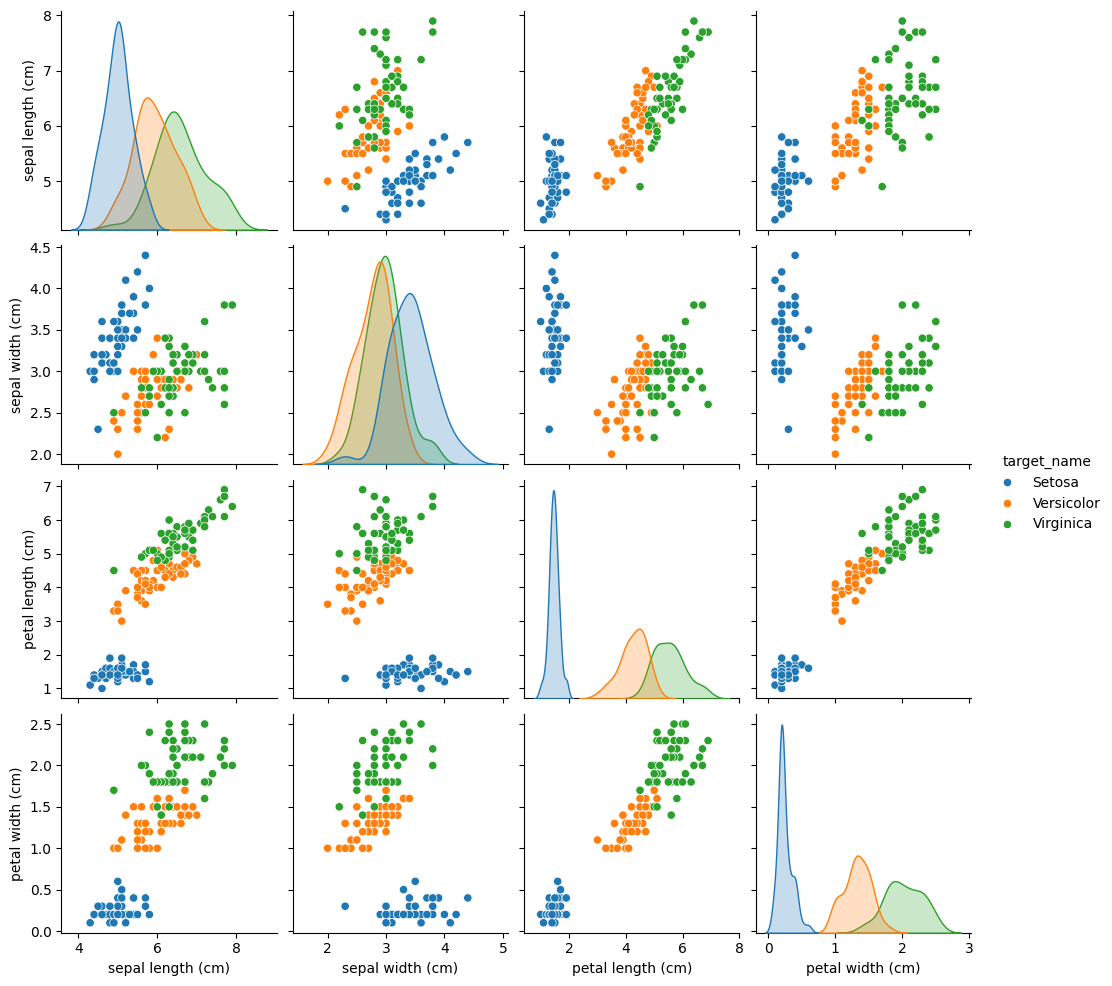

In [10]:
# Create a pairplot to visualize the data
target_names = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
df['target_name'] = df['target'].map(target_names)
sns.pairplot(df.drop(columns='target'), hue='target_name', diag_kind='kde')
plt.show()

**Interpretasi:** *Pairplot* menunjukkan bahwa ***Setosa* terpisah jelas** dari dua kelas lain pada hampir semua pasangan fitur, sedangkan *Versicolor* dan *Virginica* tumpang-tindih terutama pada fitur *sepal*. Fitur ***petal length* dan *petal width*** memberi pemisahan terbaik dan distribusinya sempit (puncak tajam, kurtosis tinggi), sehingga sangat berharga untuk klasifikasi. Ini menjelaskan mengapa kesalahan model hanya muncul di antara *Versicolor* dan *Virginica*.

### Tambahan: *decision boundary* OvR vs multinomial
Langkah 9 pada alur kerja buku meminta plot batas keputusan. Agar bisa digambar dua dimensi, dipakai dua fitur terbaik: panjang dan lebar kelopak (*petal*).

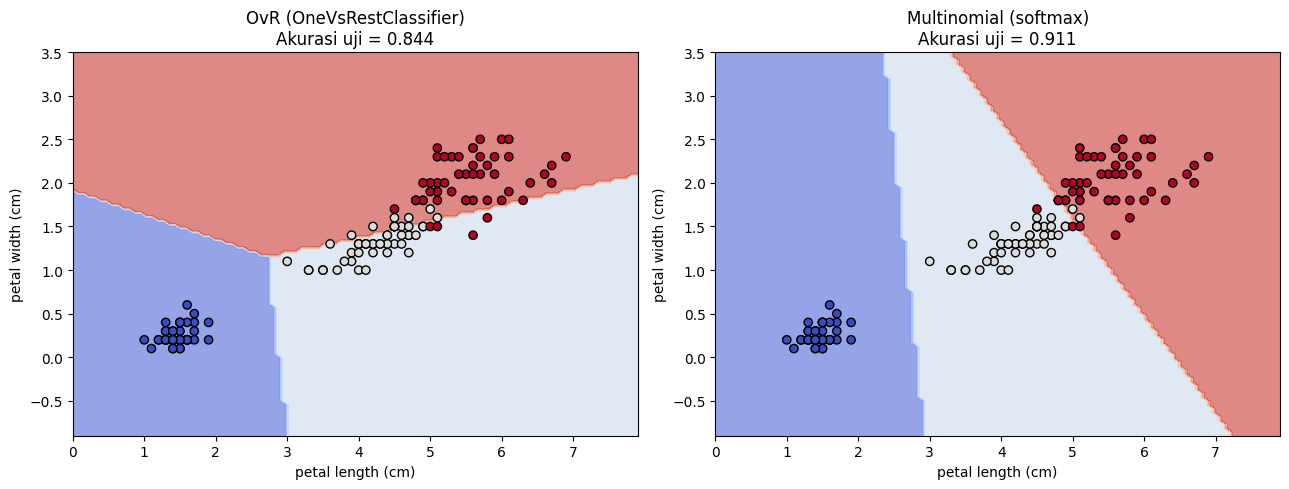

predict_proba multinomial (3 sampel pertama):
 [[0.982 0.018 0.   ]
 [0.98  0.02  0.   ]
 [0.008 0.818 0.175]]
Jumlah per baris: [1. 1. 1.]


In [11]:
# Tambahan (tidak ada di kode buku): batas keputusan memakai 2 fitur (petal length & petal width)
X2 = iris.data[:, 2:4]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.3, random_state=2024)

models_2d = {
    'OvR (OneVsRestClassifier)': OneVsRestClassifier(LogisticRegression(solver='liblinear')),
    'Multinomial (softmax)': LogisticRegression(solver='lbfgs', max_iter=1000),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, m) in zip(axes, models_2d.items()):
    m.fit(X2_train, y2_train)
    DecisionBoundaryDisplay.from_estimator(m, X2, response_method='predict',
                                           cmap=plt.cm.coolwarm, alpha=0.6, ax=ax,
                                           xlabel='petal length (cm)', ylabel='petal width (cm)')
    ax.scatter(X2[:, 0], X2[:, 1], c=y, edgecolors='k', cmap=plt.cm.coolwarm)
    ax.set_title(f'{name}\nAkurasi uji = {m.score(X2_test, y2_test):.3f}')
plt.tight_layout(); plt.show()

# Probabilitas multinomial (softmax) selalu berjumlah 1 untuk tiap sampel
np.set_printoptions(precision=3, suppress=True)
proba = multinomial_model.predict_proba(X_test[:3])
print('predict_proba multinomial (3 sampel pertama):\n', proba)
print('Jumlah per baris:', proba.sum(axis=1))

**Interpretasi:** dengan hanya dua fitur *petal*, strategi **multinomial** (akurasi uji ≈ 0,911) mengungguli **OvR** (≈ 0,844). Batas keputusan multinomial berupa tiga daerah dengan garis lurus yang bertemu rapi, sebab semua koefisien dioptimalkan **bersamaan**. Pada OvR, tiap kelas dilatih terpisah melawan "sisanya"; kelas tengah (*Versicolor*) sulit dipisahkan secara linear dari gabungan dua kelas lain sehingga batasnya melengkung dan kurang tepat. Namun pada keempat fitur (bagian sebelumnya), OvR justru sedikit lebih baik (0,956 vs 0,933), jadi **tidak ada strategi yang selalu menang**; hasilnya bergantung pada data. Terakhir, `predict_proba` multinomial selalu berjumlah 1 per sampel (mis. `[0,982; 0,018; 0,000]`), dan sampel ketiga (0,818 vs 0,175) menunjukkan model kurang yakin membedakan *Versicolor* dan *Virginica*.

### How it works
- **OvR:** satu klasifikasi biner per kelas ("kelas ini" vs "bukan kelas ini"); saat prediksi dipilih klasifikasi dengan kepercayaan tertinggi.
- **Multinomial:** satu model dengan *softmax* yang mengoptimalkan semua koefisien kelas bersamaan; lebih cocok untuk kelas yang saling lepas.

**Key considerations (dari buku):**
- *Solver:* `liblinear` umum untuk OvR; `lbfgs` atau `newton-cg` umum untuk multinomial.
- *Regularisasi* tetap bermanfaat untuk mencegah *overfitting* pada multikelas.
- *Scaling* fitur numerik sering memperbaiki performa regresi logistik.

### Key Ideas
- Regresi logistik dapat diperluas ke multikelas lewat **OvR** atau **multinomial (softmax)**.
- Pada data yang kelasnya terpisah baik (Iris), kedua strategi memberi hasil sangat mirip; perbedaannya lebih terasa pada data sulit.
- Gunakan *pairplot* dan plot batas keputusan untuk memahami struktur data sebelum percaya pada angka akurasi.

---
## 3. Regularisasi pada Regresi Logistik (*Regularization in Logistic Regression*)

### Teori
Seperti pada Bab 5, regularisasi menambahkan **penalti** pada fungsi tujuan agar koefisien tidak membesar berlebihan. Pada `LogisticRegression`, kekuatan penalti dikontrol oleh **`C` = kebalikan kekuatan regularisasi** (kebalikan dari $\alpha$ pada Ridge/Lasso):

$$\min_{\beta}\; C\sum_{i=1}^{n}\text{log-loss}_i\;+\;\text{penalti}(\beta),\qquad \text{penalti}=\begin{cases}\tfrac12\lVert\beta\rVert_2^2 & \text{L2 (Ridge)}\\[2pt]\lVert\beta\rVert_1 & \text{L1 (Lasso)}\end{cases}$$

| `C` | Regularisasi | Model | Risiko |
|---|---|---|---|
| **kecil** (mis. 0,001) | kuat | koefisien menyusut, model sederhana | *underfitting* (bias tinggi) |
| **besar** (mis. 1000) | lemah | koefisien bebas membesar | *overfitting* (variansi tinggi) |

- **L2 (Ridge):** menyusutkan koefisien mendekati nol tetapi jarang tepat nol.
- **L1 (Lasso):** dapat menolkan sebagian koefisien sehingga menghasilkan model **jarang** (*sparse*) dan **seleksi fitur** otomatis.
- Penalti sensitif terhadap skala fitur, jadi data **harus distandardisasi** lebih dulu.

### Getting ready
Kembali ke dataset Breast Cancer, kali ini data distandardisasi dengan `StandardScaler` (parameter dipelajari dari data latih saja).

In [12]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the dataset and scale it
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### How to do it
Kita membandingkan model **Ridge (L2)** dan **Lasso (L1)** dengan `C=0.1` (regularisasi cukup kuat).

In [13]:
# Create and train a Ridge (L2) regularized Logistic Regression model
ridge_model = LogisticRegression(penalty='l2', solver='liblinear', C=0.1)
ridge_model.fit(X_train, y_train)

# Create and train a Lasso (L1) regularized Logistic Regression model
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=0.1)
lasso_model.fit(X_train, y_train)

# Make predictions
y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate the Ridge model
accuracy_ridge = accuracy_score(y_test, y_pred_ridge)
print(f"Ridge (L2) Regularized Logistic Regression - Akurasi: {accuracy_ridge:.3f}")
display(styled_report(classification_report(y_test, y_pred_ridge, output_dict=True)))

# Evaluate the Lasso model
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
print(f"Lasso (L1) Regularized Logistic Regression - Akurasi: {accuracy_lasso:.3f}")
display(styled_report(classification_report(y_test, y_pred_lasso, output_dict=True)))

Ridge (L2) Regularized Logistic Regression - Akurasi: 0.982


,precision,recall,f1-score,support
0,0.985,0.970,0.977,67
1,0.981,0.990,0.986,104
accuracy,0.982,0.982,0.982,1
macro avg,0.983,0.980,0.982,171
weighted avg,0.982,0.982,0.982,171


Lasso (L1) Regularized Logistic Regression - Akurasi: 0.965


,precision,recall,f1-score,support
0,0.930,0.985,0.957,67
1,0.990,0.952,0.971,104
accuracy,0.965,0.965,0.965,1
macro avg,0.960,0.968,0.964,171
weighted avg,0.966,0.965,0.965,171


**Interpretasi:** dengan `C=0.1` pada data terstandardisasi, **Ridge** mencapai akurasi ≈ **0,982** dan **Lasso** ≈ **0,965** (171 data uji). Polanya sesuai catatan buku: Ridge unggul pada *precision* kelas *Malignant* (0,985 vs 0,930), sedangkan Lasso unggul pada *recall* kelas *Malignant* (0,985 vs 0,970). Jadi "model terbaik" bergantung pada metrik yang dipilih: bila tidak boleh ada tumor ganas yang terlewat, Lasso sedikit lebih menarik; bila ingin keseluruhan prediksi seakurat mungkin, Ridge lebih baik. Selisih hanya beberapa sampel, sehingga perlu validasi silang sebelum menyimpulkan.

### There's more…: koefisien sebagai fungsi `C`
Grafik ini memperlihatkan bagaimana koefisien membesar saat `C` naik (regularisasi melemah). Pada Lasso, banyak garis menempel di nol saat `C` kecil.

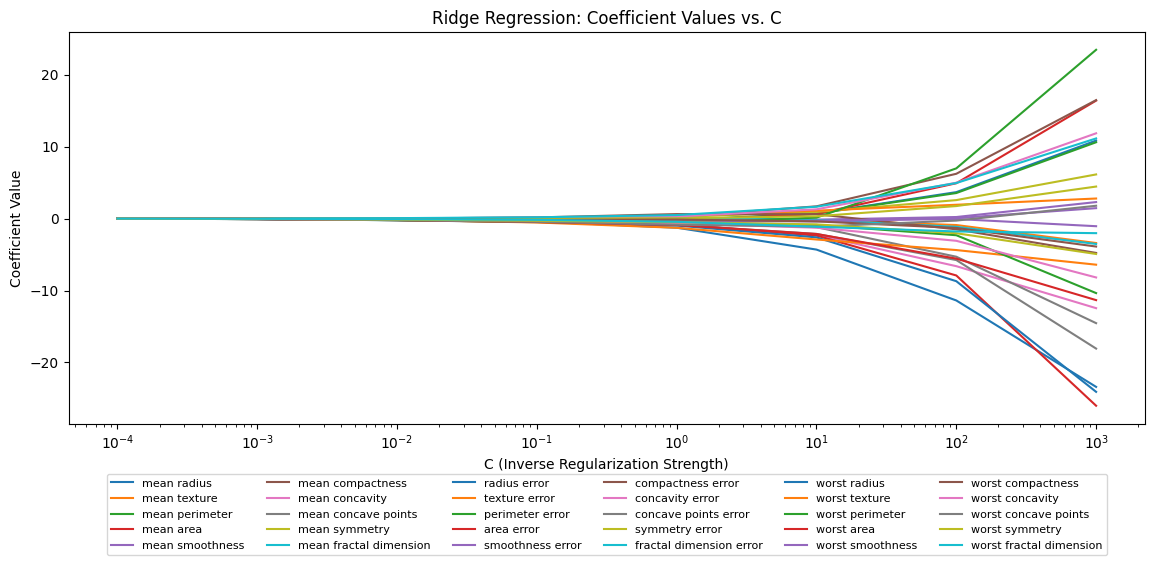

In [14]:
# Plotting coefficients for different C values (Ridge)
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_ridge = []

for C in C_values:
    ridge_model = LogisticRegression(penalty='l2', solver='liblinear', C=C)
    ridge_model.fit(X_train, y_train)
    coefs_ridge.append(ridge_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_ridge], label=feature_names[i])
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Ridge Regression: Coefficient Values vs. C')
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc='lower center', fontsize=8)
plt.tight_layout()
plt.show()

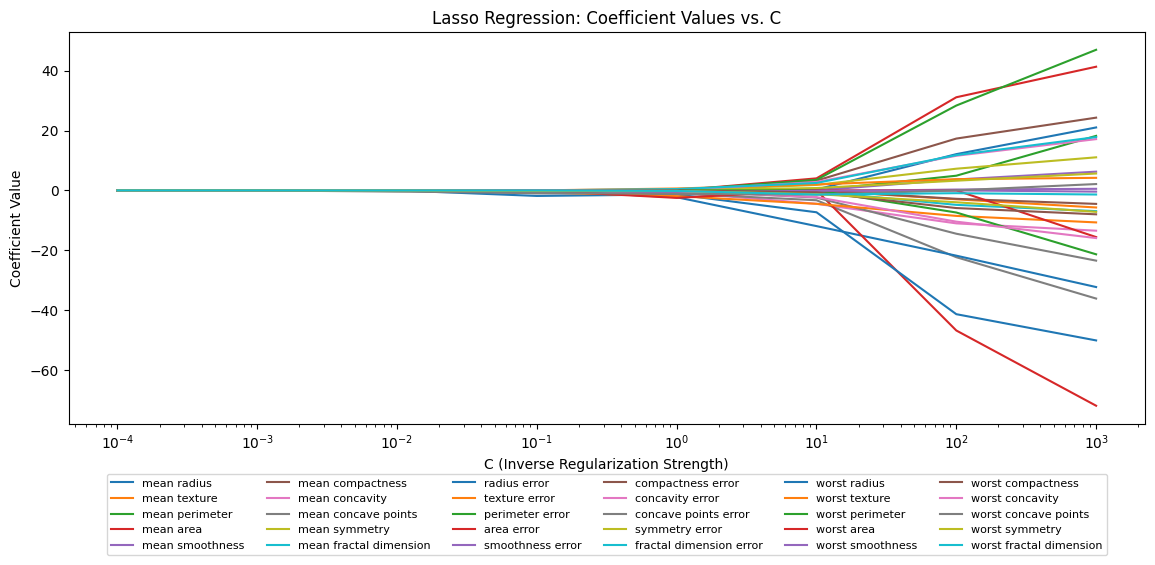

In [15]:
# Plotting coefficients for different C values (Lasso)
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])
coefs_lasso = []

for C in C_values:
    lasso_model = LogisticRegression(penalty='l1', solver='liblinear', C=C)
    lasso_model.fit(X_train, y_train)
    coefs_lasso.append(lasso_model.coef_[0])

plt.figure(figsize=(12, 6))
for i in range(X.shape[1]):
    plt.plot(C_values, [coef[i] for coef in coefs_lasso], label=feature_names[i])
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title('Lasso Regression: Coefficient Values vs. C')
plt.legend(bbox_to_anchor=(0.5, -0.35), ncol=6, loc='lower center', fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi:** pada `C` sangat kecil (regularisasi kuat) semua koefisien menempel di sekitar nol; saat `C` membesar, koefisien tumbuh dan akhirnya mencapai puluhan (pada plot Lasso sekitar −73 sampai +46 untuk `C=1000`), tanda model bebas "menyesuaikan diri" dengan data latih (variansi tinggi). Perbedaan khas: pada **Ridge** seluruh garis bergerak halus bersama-sama, sedangkan pada **Lasso** banyak garis **tepat nol** pada rentang `C` kecil dan baru "aktif" satu per satu ketika `C` naik, yaitu perilaku seleksi fitur L1.

### Tambahan: jumlah koefisien nol dan memilih `C` dengan *cross-validation*
Tabel berikut menghitung berapa koefisien yang tepat nol pada tiap nilai `C`, lalu `GridSearchCV` memilih `C` dan jenis penalti terbaik (*key consideration* buku: `C` harus disetel).

In [16]:
# Tambahan (tidak ada di kode buku): akurasi dan jumlah koefisien nol untuk tiap C
rows = []
for C_ in [0.001, 0.01, 0.1, 1, 10, 100]:
    for pen in ['l2', 'l1']:
        m = LogisticRegression(penalty=pen, solver='liblinear', C=C_).fit(X_train, y_train)
        rows.append({'C': C_, 'Penalti': pen.upper(),
                     'Akurasi latih': m.score(X_train, y_train),
                     'Akurasi uji': m.score(X_test, y_test),
                     'Koefisien = 0 (dari 30)': int((m.coef_ == 0).sum())})
display(pd.DataFrame(rows).round(3))

# Memilih C dan penalti lewat GridSearchCV
from sklearn.model_selection import GridSearchCV
param_grid = {'C': np.logspace(-3, 2, 11), 'penalty': ['l1', 'l2']}
gs = GridSearchCV(LogisticRegression(solver='liblinear'), param_grid, cv=5, scoring='accuracy')
gs.fit(X_train, y_train)
print('Parameter terbaik   :', gs.best_params_)
print(f'Skor CV terbaik     : {gs.best_score_:.3f}')
print(f'Akurasi uji model terbaik: {gs.score(X_test, y_test):.3f}')

,C,Penalti,Akurasi latih,Akurasi uji,Koefisien = 0 (dari 30)
0,0.001,L2,0.947,0.936,0
1,0.001,L1,0.364,0.392,30
2,0.010,L2,0.975,0.947,0
3,0.010,L1,0.925,0.918,28
4,0.100,L2,0.985,0.982,0
5,0.100,L1,0.977,0.965,23
6,1.000,L2,0.985,0.982,0
7,1.000,L1,0.985,0.977,15
8,10.000,L2,0.987,0.977,0
9,10.000,L1,0.987,0.965,7


Parameter terbaik   : {'C': np.float64(0.1), 'penalty': 'l2'}
Skor CV terbaik     : 0.975
Akurasi uji model terbaik: 0.982


**Interpretasi:**
- **L2 tidak pernah menolkan koefisien** (selalu 0 dari 30), hanya menyusutkannya; akurasi uji terbaik ≈ 0,982 pada `C=0.1` dan `C=1`.
- **L1 menolkan koefisien secara bertahap:** pada `C=0.001` seluruh 30 koefisien nol sehingga model hanya menebak satu kelas (akurasi uji 0,392 = proporsi kelas ganas, *underfitting* ekstrem); pada `C=0.01` tersisa 2 fitur dengan akurasi 0,918; pada `C=0.1` tersisa 7 fitur (23 nol) dengan akurasi 0,965; pada `C=1` tersisa 15 fitur dengan akurasi 0,977.
- **Tanda *overfitting*:** pada `C=100`, L1 mencapai akurasi latih 1,000 tetapi akurasi uji turun ke 0,947; L2 juga menunjukkan celah latih-uji (0,992 vs 0,959).
- `GridSearchCV` memilih **`C=0.1` dengan penalti L2** (skor CV 0,975; akurasi uji 0,982), konsisten dengan tabel di atas.

### How it works
Regularisasi menambahkan penalti pada fungsi *loss* sehingga model dicegah memberi koefisien yang terlalu besar. Hasilnya, model lebih sederhana dan lebih mampu menggeneralisasi ke data baru.

**Key considerations (dari buku):**
- *Solver:* `liblinear` mendukung L1 dan L2 untuk dataset kecil; untuk dataset besar `saga` sering menjadi pilihan.
- *Scaling:* regularisasi sensitif terhadap skala fitur, standardisasi wajib dilakukan sebelumnya.
- *Tuning:* `C` perlu disetel (grid/random search) untuk menyeimbangkan bias dan variansi.

### Key Ideas
- `C` adalah **kebalikan** kekuatan regularisasi: `C` kecil = regularisasi kuat.
- **L2** menyusutkan koefisien; **L1** menolkan sebagian koefisien (seleksi fitur).
- Pilih Ridge/Lasso berdasarkan metrik yang penting bagi masalahnya, dan tentukan `C` lewat *cross-validation*.

---
## 4. Konsep Klasifikasi Multilabel (*Multilabel Classification Concepts*)

### Teori
Perhatikan perbedaannya:

| Jenis | Label per data | Contoh |
|---|---|---|
| **Biner** | 1 dari 2 kelas | spam / bukan spam |
| **Multikelas** | tepat 1 dari $K$ kelas | jenis bunga Iris |
| **Multilabel** | **0 sampai $K$ label sekaligus** | artikel berlabel {olahraga, politik}; foto ditandai {pantai, matahari terbenam} |

Pendekatan paling sederhana adalah **transformasi relevansi biner**: latih satu regresi logistik biner **untuk setiap label** (strategi OvR). Kelemahannya, korelasi antarlabel tidak dimodelkan.

**Evaluasi multilabel** lebih rumit karena satu data punya banyak label:
- ***Subset accuracy*** (yang dihitung `accuracy_score` pada matriks label): sebuah data dianggap benar **hanya jika semua label tepat**; sangat ketat.
- ***Hamming loss***: proporsi pasangan (data, label) yang salah; lebih lunak.
- Rata-rata **micro** (menggabungkan semua keputusan), **macro** (rata-rata tiap label sama berat), **weighted**, dan **samples** (rata-rata per data) pada *classification report*.

### Getting ready
Dataset dibangkitkan sintetis dengan `make_multilabel_classification`: 1000 sampel, 20 fitur, 5 kelas, rata-rata 2 label per sampel (`n_labels` tidak menjamin jumlah label per data, hanya rata-ratanya).

In [17]:
# Load the libraries
from sklearn.datasets import make_multilabel_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
X, y = make_multilabel_classification(n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024)
df = pd.DataFrame(X, columns=[f'feature_{i}' for i in range(X.shape[1])])
df['target'] = list(y)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('Bentuk X:', X.shape, '| bentuk y (matriks label):', y.shape)
print('5 baris pertama y:\n', y[:5])

Bentuk X: (1000, 20) | bentuk y (matriks label): (1000, 5)
5 baris pertama y:
 [[0 1 0 0 0]
 [0 0 0 0 0]
 [0 1 1 0 0]
 [0 0 1 0 0]
 [1 1 0 0 1]]


### How to do it
Karena ada banyak label, kita melatih **satu model untuk tiap label** (kolom `y`).

In [18]:
# Since we have multiple labels, we need to train a separate model for each label
models = []
y_pred_all = []

# Train a model for each label (column) in y
for i in range(y_train.shape[1]):
    # Create and train model for this label
    model = LogisticRegression(solver='liblinear')
    model.fit(X_train, y_train[:, i])
    models.append(model)

    # Make predictions for this label
    y_pred_label = model.predict(X_test)
    y_pred_all.append(y_pred_label)

# Convert predictions list to array and transpose to match original format
y_pred = np.array(y_pred_all).T

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)   # pada multilabel = subset accuracy
print(f'Subset accuracy (semua label harus tepat): {accuracy:.3f}')
print("Classification Report:")
display(styled_report(classification_report(y_test, y_pred, zero_division=1, output_dict=True)))

Subset accuracy (semua label harus tepat): 0.340
Classification Report:


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562


**Interpretasi:** *subset accuracy* hanya **0,340**: hanya 34% data uji yang kelima labelnya tepat semua. Angka ini sangat ketat dan tidak boleh dibaca seperti akurasi biasa. Rapor per label lebih informatif: label 0 dan 1 (F1 ≈ 0,81 dan 0,82) paling baik karena paling sering muncul, sedangkan label 3 paling buruk (*recall* hanya 0,176, F1 0,286) dan label 2 serta 4 juga lemah (*recall* 0,333 dan 0,477). *Precision* yang lebih tinggi daripada *recall* pada label jarang menandakan model terlalu "pelit" memprediksi label tersebut. Rata-rata *micro* F1 (0,701) lebih tinggi daripada *macro* F1 (0,577) karena *micro* didominasi label yang sering muncul, sedangkan *macro* memberi bobot sama pada label jarang.

### Analisis *co-occurrence* label
Fungsi berikut (dari buku) menunjukkan seberapa sering dua label muncul bersamaan serta kombinasi label yang paling umum.

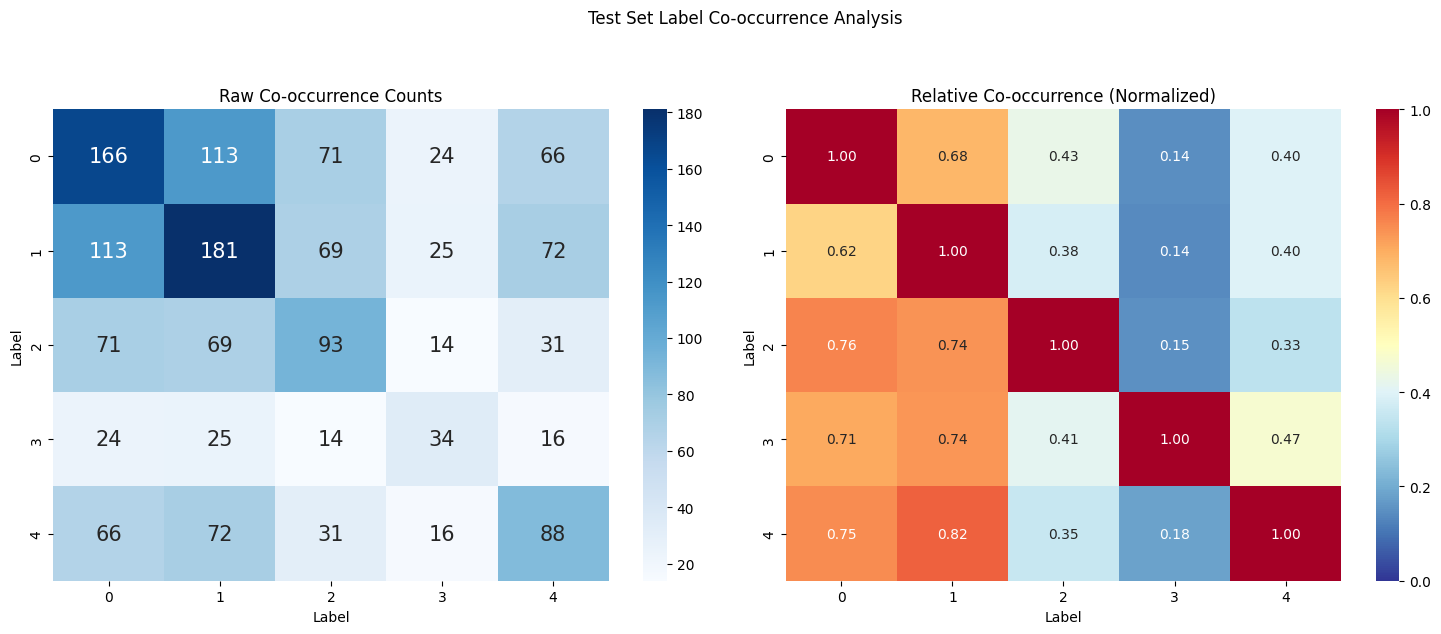


Label Statistics:
Total samples: 300

Label frequencies:
Label 0: 166 samples (55.3%)
Label 1: 181 samples (60.3%)
Label 2: 93 samples (31.0%)
Label 3: 34 samples (11.3%)
Label 4: 88 samples (29.3%)

Most common label combinations:
Combination [0 0 0 0 0]: 52 samples (17.3%)
Combination [0 1 0 0 0]: 34 samples (11.3%)
Combination [1 1 0 0 0]: 28 samples (9.3%)
Combination [1 1 1 0 0]: 25 samples (8.3%)
Combination [1 1 0 0 1]: 24 samples (8.0%)


In [19]:
# Create a detailed label co-occurrence visualization
def plot_label_cooccurrence(y, title="Label Co-occurrence Analysis"):
    # Compute raw co-occurrence counts
    cooccurrence = y.T @ y

    # Compute relative co-occurrence (normalized by diagonal)
    # This shows what percentage of time label i occurs with label j
    diag = np.diag(cooccurrence)
    relative_cooccurrence = cooccurrence / diag[:, None]

    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # Plot raw co-occurrence
    sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Blues',
                ax=ax1, annot_kws={"fontsize": 15})
    ax1.set_title('Raw Co-occurrence Counts')
    ax1.set_xlabel('Label')
    ax1.set_ylabel('Label')

    # Plot relative co-occurrence
    sns.heatmap(relative_cooccurrence, annot=True, fmt='.2f',
                cmap='RdYlBu_r', ax=ax2, annot_kws={"fontsize": 10},
                vmin=0, vmax=1)
    ax2.set_title('Relative Co-occurrence (Normalized)')
    ax2.set_xlabel('Label')
    ax2.set_ylabel('Label')

    plt.suptitle(title, y=1.05)
    plt.tight_layout()
    plt.show()

    # Print additional statistics
    print("\nLabel Statistics:")
    print(f"Total samples: {len(y)}")
    print("\nLabel frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        percentage = count / len(y) * 100
        print(f"Label {i}: {count} samples ({percentage:.1f}%)")

    print("\nMost common label combinations:")
    # Get unique combinations and their counts
    unique_combinations = np.unique(y, axis=0, return_counts=True)
    sorted_idx = np.argsort(-unique_combinations[1])  # Sort by count (descending)
    for combo, count in zip(unique_combinations[0][sorted_idx][:5],
                            unique_combinations[1][sorted_idx][:5]):
        percentage = count / len(y) * 100
        print(f"Combination {combo}: {count} samples ({percentage:.1f}%)")

# Use the function on your test data
plot_label_cooccurrence(y_test, "Test Set Label Co-occurrence Analysis")

**Interpretasi:** frekuensi label pada data uji tidak seimbang: label 1 muncul pada 60,3% data, label 0 pada 55,3%, label 2 pada 31,0%, label 4 pada 29,3%, dan label 3 hanya 11,3%. Ini menjelaskan mengapa label 3 paling sulit dipelajari. Sebanyak **17,3% data tidak memiliki label sama sekali** (kombinasi `[0 0 0 0 0]`), dan kombinasi {label 0, label 1} muncul berulang di lima kombinasi teratas, tanda ada **ketergantungan antarlabel**. Strategi satu-model-per-label mengabaikan ketergantungan ini; pendekatan lanjutan seperti *classifier chains* dapat memanfaatkannya (tidak diimplementasikan di buku).

### Tambahan: metrik multilabel dan pembungkus `OneVsRestClassifier`
Scikit-learn menyediakan `OneVsRestClassifier` yang mengotomatiskan loop di atas; hasilnya harus identik. Kita juga membandingkan beberapa metrik multilabel dengan baseline sederhana (selalu memprediksi label yang paling sering muncul).

In [20]:
# Tambahan (tidak ada di kode buku)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import hamming_loss, f1_score

ovr = OneVsRestClassifier(LogisticRegression(solver='liblinear')).fit(X_train, y_train)
y_pred_ovr = ovr.predict(X_test)
print('Hasil OneVsRestClassifier identik dengan loop manual?', np.array_equal(y_pred_ovr, y_pred))

# Baseline: untuk tiap label prediksikan nilai mayoritas data latih
y_base = np.tile((y_train.mean(axis=0) >= 0.5).astype(int), (len(y_test), 1))

def multilabel_metrics(y_true, y_hat):
    return {'Subset accuracy': accuracy_score(y_true, y_hat),
            'Hamming loss': hamming_loss(y_true, y_hat),
            'F1 micro': f1_score(y_true, y_hat, average='micro', zero_division=0),
            'F1 macro': f1_score(y_true, y_hat, average='macro', zero_division=0),
            'F1 samples': f1_score(y_true, y_hat, average='samples', zero_division=0)}

pd.DataFrame({'Regresi logistik (OvR)': multilabel_metrics(y_test, y_pred),
              'Baseline mayoritas': multilabel_metrics(y_test, y_base)}).round(3)

Hasil OneVsRestClassifier identik dengan loop manual? True


,Regresi logistik (OvR),Baseline mayoritas
Subset accuracy,0.340,0.093
Hamming loss,0.209,0.312
F1 micro,0.701,0.597
F1 macro,0.577,0.293
F1 samples,0.620,0.533


**Interpretasi:** `OneVsRestClassifier` menghasilkan prediksi **identik** dengan loop manual (`True`), jadi cukup dipakai sebagai jalan pintas. Dibanding baseline mayoritas, model lebih baik pada semua metrik: *subset accuracy* 0,340 vs 0,093, *Hamming loss* 0,209 vs 0,312 (lebih kecil lebih baik; artinya sekitar 21% dari 1.500 keputusan label salah), dan F1 *macro* 0,577 vs 0,293. Perhatikan bahwa F1 *micro* baseline (0,597) tampak cukup tinggi karena memprediksi label yang sering muncul sebagai positif, sehingga satu metrik saja bisa menyesatkan. Catatan: F1 *samples* di sini 0,620, sedangkan di *classification report* 0,680, karena 17,3% data tidak punya label dan laporan memakai `zero_division=1` (kasus "tidak ada label dan tidak ada prediksi" dihitung sempurna), sedangkan di sini `zero_division=0`.

### How it works
Klasifikasi multilabel memprediksi **beberapa label biner** untuk setiap data. Dengan strategi OvR, tiap label punya klasifikasi biner sendiri yang belajar membedakan "data berlabel ini" dari "data tanpa label ini". `make_multilabel_classification()` membangkitkan fitur dan matriks label sintetis; kinerjanya dibaca lewat *classification report* (precision, recall, F1 per label) dan metrik khusus multilabel.

### Key Ideas
- Multilabel ≠ multikelas: satu data boleh punya **banyak label sekaligus**.
- Pendekatan sederhana: **satu model biner per label** (`OneVsRestClassifier`); tidak memodelkan korelasi antarlabel.
- Gunakan metrik yang sesuai: *subset accuracy* sangat ketat, *Hamming loss* dan F1 (micro/macro/samples) memberi gambaran lebih adil.

---
## 5. Metrik Evaluasi Model (*Model Evaluation Metrics*)

### Teori
Selain akurasi, precision, recall, dan F1 (lihat tabel pada subbab 1), dua alat penting untuk model probabilistik adalah:

- **Kurva ROC (*Receiver Operating Characteristic*)** memplot **TPR** (*recall*) terhadap **FPR** pada semua ambang keputusan:
$$TPR=\frac{TP}{TP+FN},\qquad FPR=\frac{FP}{FP+TN}$$
  Garis diagonal putus-putus mewakili tebakan acak.
- **AUC (*Area Under the Curve*)** meringkas ROC menjadi satu angka antara 0 dan 1. AUC = 0,5 setara tebakan acak; AUC = 1 berarti pemisahan sempurna. Secara probabilistik, AUC adalah peluang model memberi skor lebih tinggi pada sampel positif acak dibanding sampel negatif acak.

> Memilih metrik adalah keputusan bisnis: bila **melewatkan kasus positif** mahal (diagnosis penyakit), utamakan *recall*; bila **alarm palsu** mahal (filter spam), utamakan *precision*; F1 dan AUC dipakai untuk ringkasan seimbang.

### Getting ready
Dataset Breast Cancer lagi, dengan pembagian 70:30.

In [21]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.datasets import load_breast_cancer
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### How to do it
Kita melatih regresi logistik, lalu menghitung semua metrik dan menggambar kurva ROC.

Accuracy 0.94
Precision 0.94
Recall 0.95
F1 Score 0.95
ROC AUC 0.99
Classification Report:


,precision,recall,f1-score,support
0,0.924,0.910,0.917,67
1,0.943,0.952,0.947,104
accuracy,0.936,0.936,0.936,1
macro avg,0.934,0.931,0.932,171
weighted avg,0.936,0.936,0.936,171


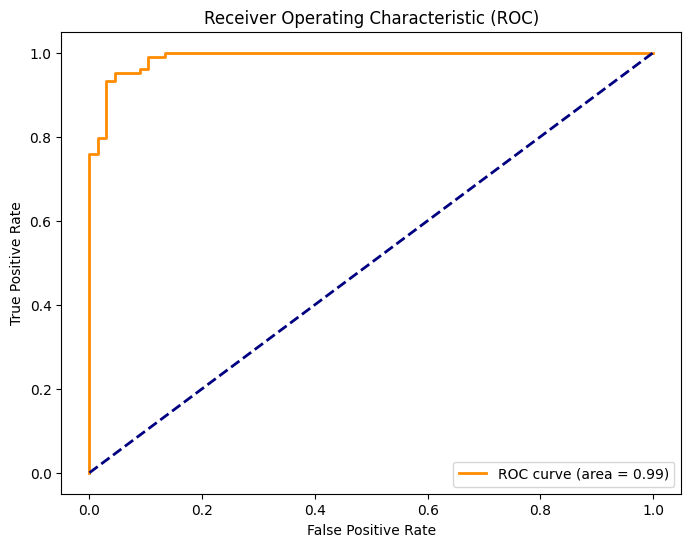

In [22]:
# Load the model
model = LogisticRegression(solver='liblinear')

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

# Print the metrics
print(f"Accuracy {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall {recall:.2f}")
print(f"F1 Score {f1:.2f}")
print(f"ROC AUC {roc_auc:.2f}")
print("Classification Report:")
display(styled_report(classification_report(y_test, y_pred, zero_division=1, output_dict=True)))

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Interpretasi:** pada 171 data uji, model mencapai akurasi ≈ 0,94, *precision* 0,94, *recall* 0,95, F1 0,95, dan **ROC AUC ≈ 0,99**. Kurva ROC melengkung rapat ke sudut kiri-atas, jauh dari garis diagonal tebakan acak: model hampir selalu memberi skor lebih tinggi pada tumor jinak dibanding tumor ganas, di berbagai ambang. Akurasi 0,94 dan AUC 0,99 tidak bertentangan: akurasi dihitung pada **satu** ambang (0,5), sedangkan AUC merangkum **semua** ambang sehingga menunjukkan potensi model bila ambang disetel (lihat tabel ambang pada subbab 1).

### Tambahan: *precision-recall curve* dan AUC yang divalidasi silang
Pada data tak seimbang, kurva *precision-recall* lebih informatif daripada ROC. Skor tunggal dari satu pembagian data juga bisa bias, sehingga AUC dihitung ulang dengan *5-fold cross-validation* memakai *pipeline* (scaling di dalam fold agar bebas *data leakage*, lihat Bab 1 dan 2).

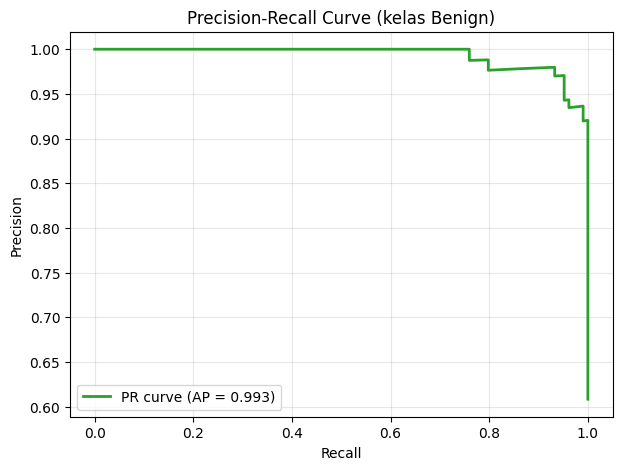

AUC per fold      : [0.995 0.997 0.997 0.988 1.   ]
AUC rata-rata CV  : 0.995 (+/- 0.004)


In [23]:
# Tambahan (tidak ada di kode buku)
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

prec, rec, _ = precision_recall_curve(y_test, y_prob)
ap = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(rec, prec, color='tab:green', lw=2, label=f'PR curve (AP = {ap:.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall Curve (kelas Benign)')
plt.legend(loc='lower left'); plt.grid(alpha=0.3); plt.show()

pipe = make_pipeline(StandardScaler(), LogisticRegression(solver='liblinear'))
cv_auc = cross_val_score(pipe, X, y, cv=5, scoring='roc_auc')
print('AUC per fold      :', np.round(cv_auc, 3))
print(f'AUC rata-rata CV  : {cv_auc.mean():.3f} (+/- {cv_auc.std():.3f})')

**Interpretasi:** *average precision* (luas di bawah kurva PR) ≈ **0,993**, dan AUC rata-rata dari 5-*fold cross-validation* ≈ **0,995** (rentang per *fold* 0,988–1,000, simpangan baku 0,004). Konsistennya skor antar-*fold* menunjukkan bahwa performa tinggi ini bukan kebetulan satu pembagian data. Kurva PR memperlihatkan *precision* tetap tinggi hingga *recall* mendekati 1; baru turun pada ujung kanan, yaitu saat ambang dibuat sangat longgar.

### Key Ideas
- Satu metrik tidak pernah cukup; baca **precision, recall, F1, ROC-AUC** bersama dengan *confusion matrix*.
- **ROC/AUC** menilai kemampuan memisahkan kelas di **semua ambang**; **PR curve** lebih tepat saat kelas tak seimbang.
- Validasi silang memberi estimasi performa yang lebih stabil daripada satu kali pembagian data.

---
## 6. Latihan Praktik (*Practical Exercises with Advanced Logistic Regression*)

Berikut solusi ketiga latihan dari buku (diambil dari berkas *Exercise Solutions* pada repositori resmi), dilengkapi interpretasi.

### Latihan 1: Regresi Logistik Teregularisasi (Lasso dan Ridge)
Membangun model regresi logistik pada dataset Breast Cancer dengan regularisasi Lasso (L1) dan Ridge (L2).

In [24]:
# Load libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score   # Catatan: import ini tidak ada di solusi asli buku
import pandas as pd

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a Lasso regularized Logistic Regression model
lasso_model = LogisticRegression(penalty='l1', solver='liblinear', max_iter=10000, C=0.1)
lasso_model.fit(X_train, y_train)

# Make predictions with the Lasso model
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate the Lasso model performance
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
print(f"Lasso Model Accuracy: {accuracy_lasso:.2f}")

# Tambahan: model Ridge (L2) dengan pengaturan yang sama, sesuai judul latihan
ridge_model = LogisticRegression(penalty='l2', solver='liblinear', max_iter=10000, C=0.1)
ridge_model.fit(X_train, y_train)
print(f"Ridge Model Accuracy: {accuracy_score(y_test, ridge_model.predict(X_test)):.2f}")

Lasso Model Accuracy: 0.95
Ridge Model Accuracy: 0.94


In [25]:
# Tambahan (tidak ada di kode buku): pengaruh scaling pada model teregularisasi
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rows = []
for pen in ['l1', 'l2']:
    raw = LogisticRegression(penalty=pen, solver='liblinear', max_iter=10000, C=0.1).fit(X_train, y_train)
    scaled = make_pipeline(StandardScaler(),
                           LogisticRegression(penalty=pen, solver='liblinear', max_iter=10000, C=0.1)).fit(X_train, y_train)
    rows.append({'Penalti': pen.upper(),
                 'Akurasi uji (tanpa scaling)': raw.score(X_test, y_test),
                 'Koef = 0 (tanpa scaling)': int((raw.coef_ == 0).sum()),
                 'Akurasi uji (dengan scaling)': scaled.score(X_test, y_test),
                 'Koef = 0 (dengan scaling)': int((scaled[-1].coef_ == 0).sum())})
pd.DataFrame(rows).set_index('Penalti').round(3)

,Akurasi uji (tanpa scaling),Koef = 0 (tanpa scaling),Akurasi uji (dengan scaling),Koef = 0 (dengan scaling)
Penalti,,,,
L1,0.947,23,0.965,23
L2,0.942,0,0.982,0


**Interpretasi:** tanpa *scaling*, Lasso mencapai akurasi **0,95** dan Ridge **0,94**. Setelah fitur distandardisasi, akurasi naik menjadi **0,965 (Lasso)** dan **0,982 (Ridge)**, kenaikan ±1,8 dan ±4,0 poin persentase. Penalti L1/L2 menghukum besar-kecilnya koefisien, sehingga fitur berskala besar (mis. `area` ribuan) diperlakukan tidak adil bila tidak distandardisasi; inilah alasan *key consideration* buku, "regularisasi sensitif terhadap skala fitur". Lasso pada `C=0.1` menolkan **23 dari 30** koefisien (menyisakan 7 fitur) dengan akurasi tetap tinggi, bukti seleksi fitur otomatis.

### Latihan 2: Evaluasi Regresi Logistik Multikelas
Memakai regresi logistik multinomial pada dataset Iris.

In [26]:
# Load the libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score   # Catatan: import ini tidak ada di solusi asli buku

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a Multinomial Logistic Regression model
multinomial_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multinomial_model.fit(X_train, y_train)

# Make predictions with the Multinomial model
y_pred_multinomial = multinomial_model.predict(X_test)

# Evaluate the Multinomial model performance
accuracy_multinomial = accuracy_score(y_test, y_pred_multinomial)
print(f"Multinomial Model Accuracy: {accuracy_multinomial:.2f}")

Multinomial Model Accuracy: 0.93


**Interpretasi:** model multinomial mencapai akurasi **0,93** (42 dari 45), identik dengan hasil pada subbab 2. Hasil yang konsisten ini wajar karena data dan *random_state* yang dipakai sama.

### Latihan 3: Visualisasi Hasil Regresi Logistik
Menggambar *decision boundary* model regresi logistik pada dataset biner sintetis (2 fitur).

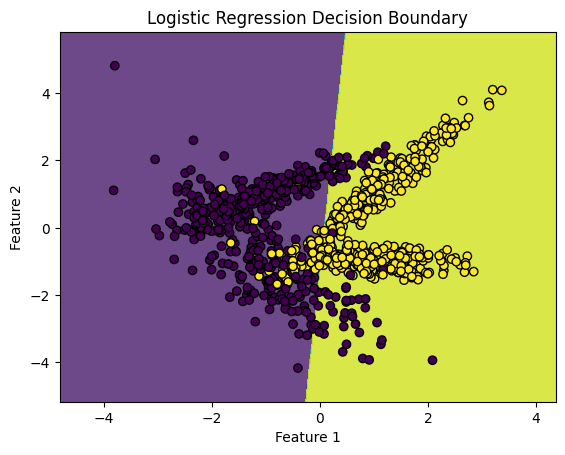

Akurasi uji: 0.897


In [27]:
# Load libraries for visualization and dataset creation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Create synthetic dataset for binary classification
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2, n_redundant=0, random_state=2024)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a Logistic Regression model
logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

# Create a mesh grid for plotting decision boundaries
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Predict class labels across the grid
Z = logistic_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
print(f'Akurasi uji: {logistic_model.score(X_test, y_test):.3f}')

Tambahan: peta **probabilitas** $P(Y=1)$ (bukan hanya label) dan garis keputusan pada $P=0{,}5$.

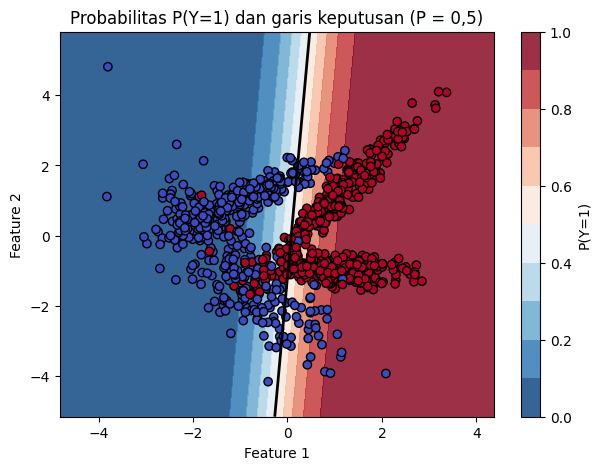

In [28]:
# Tambahan (tidak ada di kode buku): peta probabilitas dari predict_proba
proba_grid = logistic_model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

plt.figure(figsize=(7, 5))
cs = plt.contourf(xx, yy, proba_grid, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.85)
plt.colorbar(cs, label='P(Y=1)')
plt.contour(xx, yy, proba_grid, levels=[0.5], colors='k', linewidths=2)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap='coolwarm')
plt.title('Probabilitas P(Y=1) dan garis keputusan (P = 0,5)')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2'); plt.show()

**Interpretasi:** akurasi uji ≈ **0,897**. *Decision boundary* regresi logistik berupa **garis lurus** yang memisahkan ruang menjadi dua daerah; kesalahan terjadi pada titik yang berada di sisi yang salah karena kedua kelas pada data sintetis ini memang tumpang-tindih. Peta probabilitas memperlihatkan perbedaan penting dibanding peta label: probabilitas berubah **bertahap** (pola sigmoid) dari merah ke biru, dengan pita ketidakpastian di sekitar garis P = 0,5; makin jauh dari garis, model makin yakin.

---
## 7. Ringkasan Bab

Bab ini memperluas **regresi logistik** dari klasifikasi biner dasar ke **multikelas**, **regularisasi**, dan **multilabel**, lalu menutupnya dengan **metrik evaluasi** yang tepat untuk menilai model klasifikasi.

### Rangkuman Konsep dan Fungsi
| Subbab | Konsep utama | Kelas/Fungsi scikit-learn |
|---|---|---|
| Ikhtisar regresi logistik | Sigmoid, log-odds, MLE, ambang keputusan | `LogisticRegression`, `predict_proba`, `confusion_matrix` |
| Multikelas | One-vs-Rest, multinomial (softmax) | `OneVsRestClassifier`, `LogisticRegression(solver='lbfgs')` |
| Regularisasi | Penalti L1/L2, `C` = kebalikan kekuatan | `LogisticRegression(penalty=, C=)`, `GridSearchCV` |
| Multilabel | Satu model biner per label, subset accuracy, Hamming loss | `make_multilabel_classification`, `OneVsRestClassifier`, `hamming_loss` |
| Metrik evaluasi | Precision, recall, F1, ROC, AUC, PR curve | `classification_report`, `roc_curve`, `auc`, `precision_recall_curve` |
| Latihan | Lasso/Ridge, multinomial, batas keputusan | `DecisionBoundaryDisplay`/`contourf`, `train_test_split` |

**Pesan utama:** regresi logistik adalah *baseline* klasifikasi yang cepat dan mudah ditafsirkan. Standardisasi fitur, setel `C` dengan *cross-validation*, pilih metrik sesuai biaya kesalahan (bukan hanya akurasi), dan gunakan strategi OvR/multinomial/multilabel sesuai struktur label.